In [ ]:
# These notebooks live in notebooks/d1_dev/ but use paths relative to the repo root
# (data/, protocol/, reports/, ...) and import from src/: go back to the root first.
# The test makes it harmless to run twice, or to run from the root.
import os
from pathlib import Path

if not Path("src").exists():
    os.chdir(Path.cwd().parents[1])

# 00 — Data preparation

Builds `protocol/manifest.csv`: one row per file, with its metadata, `drop_reason` and `split`, shared by the whole group.
Cleaning only marks rows; no file is deleted.
Images are read from `LEYENDA_DATA_DIR`, otherwise `data/Datasets`.

In [1]:
import io
import os
import time
import hashlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

SEED = 42
# Image folder: LEYENDA_DATA_DIR if set, otherwise data/Datasets (relative to the repo root).
DATA_DIR = Path(os.environ.get("LEYENDA_DATA_DIR", "data/Datasets"))
MANIFEST = Path("protocol") / "manifest.csv"
IMAGE_EXTENSIONS = {"jpg", "jpeg", "png"}   # compared in lower case

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Image folder not found: {DATA_DIR}. "
        "Set LEYENDA_DATA_DIR or put the data in data/Datasets.")
CLASSES = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
print("DATA_DIR:", DATA_DIR)
print("Classes :", CLASSES)

DATA_DIR: data/Datasets
Classes : ['Painting', 'Photo', 'Schematics', 'Sketch', 'Text']


## Inventory

Every file of the 5 folders is listed; only `.jpg`, `.jpeg` and `.png` are decoded in full (`.load()`, to catch truncated files).
Other files are marked `not_an_image` and decoding failures `unreadable`.
Label: Photo = 1, the other 4 origins = 0.

In [2]:
def inspect(fp):
    """Read a file once: md5 + dimensions + mode + full decoding test."""
    data = fp.read_bytes()
    row = {"md5": hashlib.md5(data).hexdigest(),
           "width": np.nan, "height": np.nan, "mode": "", "drop_reason": "", "error": ""}
    if fp.suffix.lower().lstrip(".") not in IMAGE_EXTENSIONS:
        row["drop_reason"] = "not_an_image"
        return row
    try:
        with Image.open(io.BytesIO(data)) as im:
            row["width"], row["height"], row["mode"] = im.size[0], im.size[1], im.mode
            im.load()  # actually decodes every pixel
    except Exception as e:
        row["drop_reason"] = "unreadable"
        row["error"] = f"{type(e).__name__}: {e}"
    return row

files = [(cls, fp) for cls in CLASSES
         for fp in sorted((DATA_DIR / cls).iterdir()) if fp.is_file()]

t0 = time.time()
# Threads: disk reads, md5 and Pillow decoding release the GIL.
with ThreadPoolExecutor(max_workers=16) as ex:
    infos = list(ex.map(lambda t: inspect(t[1]), files))
print(f"{len(files)} files inspected in {time.time() - t0:.1f}s")

df = pd.DataFrame(infos)
df.insert(0, "path", [fp.relative_to(DATA_DIR).as_posix() for _, fp in files])
df.insert(1, "origin", [cls for cls, _ in files])
df.insert(2, "label", (df["origin"] == "Photo").astype(int))
df.insert(3, "ext", [fp.suffix.lower().lstrip(".") for _, fp in files])

41399 files inspected in 48.7s


In [3]:
# Number of files, extensions and colour modes per origin
display(pd.crosstab(df["origin"], df["ext"], margins=True))
display(pd.crosstab(df["origin"], df["mode"].replace("", "(none)"), margins=True))

ext,jpg,png,All
origin,,,
Painting,10000,0,10000
Photo,9993,0,9993
Schematics,10000,0,10000
Sketch,606,800,1406
Text,10000,0,10000
All,40599,800,41399


mode,CMYK,L,P,RGB,RGBA,All
origin,,,,,,
Painting,1,82,5,9907,5,10000
Photo,0,25,0,9968,0,9993
Schematics,0,116,0,9884,0,10000
Sketch,0,868,0,538,0,1406
Text,0,0,0,10000,0,10000
All,1,1091,5,40297,5,41399


In [4]:
# Files that are not images, or that could not be decoded
df.loc[df["drop_reason"].isin(["not_an_image", "unreadable"]), ["path", "origin", "ext", "drop_reason", "error"]]

,path,origin,ext,drop_reason,error


What we observe:

- 41,399 files inspected; the table of non-image or unreadable files is empty.
- Sketch has 1,406 files (800 PNG, 868 in mode L); the other origins have 9,993 to 10,000.

## Cleaning

### Exact duplicates

Same md5 and same label: the first path in alphabetical order is kept, the others are marked `exact_duplicate`; same md5 with different labels: the whole group is marked `label_conflict`.
Why: a duplicate in both train and test would be scored on an image the model has already seen.

In [5]:
readable = df["drop_reason"] == ""
sub = df[readable].sort_values("path")          # alphabetical order of paths
groups = sub.groupby("md5")
group_size = groups["path"].transform("size")
n_labels = groups["label"].transform("nunique")
rank = groups.cumcount()                         # 0 = first path of the group, the one we keep

conflict = sub.index[((group_size > 1) & (n_labels > 1)).to_numpy()]
duplicate = sub.index[((group_size > 1) & (n_labels == 1) & (rank > 0)).to_numpy()]
df.loc[conflict, "drop_reason"] = "label_conflict"
df.loc[duplicate, "drop_reason"] = "exact_duplicate"

print(f"md5 groups with more than one file: {(groups.size() > 1).sum()}")
pd.crosstab(df["origin"], df["drop_reason"].replace("", "(kept)"), margins=True)

md5 groups with more than one file: 380


drop_reason,(kept),exact_duplicate,All
origin,,,
Painting,9996,4,10000
Photo,9993,0,9993
Schematics,9309,691,10000
Sketch,1406,0,1406
Text,9999,1,10000
All,40703,696,41399


In [6]:
# Duplicate groups spanning several origins (e.g. the same image in Painting and Sketch)
multi = df[readable].groupby("md5").filter(lambda g: len(g) > 1 and g["origin"].nunique() > 1)
print(f"{multi['md5'].nunique()} multi-origin groups")
multi.sort_values(["md5", "path"])[["md5", "path", "origin", "label", "drop_reason"]].head(30)

0 multi-origin groups


,md5,path,origin,label,drop_reason


What we observe:

- 696 files marked `exact_duplicate`, 691 of them in Schematics.
- 0 multi-origin groups; the table has no `label_conflict` column.

### Too small

Images whose shortest side is under `MIN_SIDE_PX` = 32 px are marked `too_small`; the 32 px threshold is proposed after visual inspection, to be validated by the group.
Why: the smallest images are 1×1 to 3×3 squares and strips 1 to 3 px wide (table below).
It marks 401 images, all Schematics; 64 px would mark 621 and 128 px 993 Schematics plus 2 Photos.

In [7]:
df["min_side"] = df[["width", "height"]].min(axis=1)
kept = df["drop_reason"] == ""
display(df[kept].groupby("origin")["min_side"].describe(percentiles=[.01, .05, .25, .5]).round(0))

# How many kept images would fall below each candidate threshold
candidates = [32, 64, 96, 128, 160, 224]
pd.DataFrame({f"< {s} px": df[kept].groupby("origin")["min_side"].apply(lambda m: (m < s).sum())
              for s in candidates})

,count,mean,std,min,1%,5%,25%,50%,max
origin,,,,,,,,,
Painting,9996.0,856.0,554.0,201.0,317.0,369.0,512.0,712.0,6232.0
Photo,9993.0,444.0,64.0,109.0,281.0,333.0,425.0,428.0,640.0
Schematics,9309.0,549.0,504.0,1.0,3.0,38.0,279.0,460.0,7273.0
Sketch,1406.0,810.0,346.0,411.0,411.0,411.0,414.0,1111.0,1111.0
Text,9999.0,568.0,74.0,360.0,360.0,385.0,595.0,595.0,612.0


,< 32 px,< 64 px,< 96 px,< 128 px,< 160 px,< 224 px
origin,,,,,,
Painting,0,0,0,0,0,1
Photo,0,0,0,2,5,36
Schematics,401,621,800,993,1188,1675
Sketch,0,0,0,0,0,0
Text,0,0,0,0,0,0


In [8]:
def contact_sheet(rows, n_cols=5, title=None):
    """Show images (manifest rows) at the same display size, with their dimensions."""
    n_rows = max(1, int(np.ceil(len(rows) / n_cols)))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
        with Image.open(DATA_DIR / r["path"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"{r['origin']}  {int(r['width'])}×{int(r['height'])}", fontsize=9)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# The 20 smallest kept images
smallest = df[kept].nsmallest(20, "min_side")
smallest[["path", "origin", "width", "height", "mode"]]

,path,origin,width,height,mode
20042,Schematics/schematics_00050.jpg,Schematics,1,64,RGB
22205,Schematics/schematics_02213.jpg,Schematics,1,1,RGB
22587,Schematics/schematics_02595.jpg,Schematics,1,64,RGB
24515,Schematics/schematics_04523.jpg,Schematics,1,64,RGB
25822,Schematics/schematics_05830.jpg,Schematics,1,1,L
26458,Schematics/schematics_06466.jpg,Schematics,1,256,RGB
28654,Schematics/schematics_08662.jpg,Schematics,6142,1,RGB
29228,Schematics/schematics_09236.jpg,Schematics,6141,1,RGB
20142,Schematics/schematics_00150.jpg,Schematics,2,2,L
20306,Schematics/schematics_00314.jpg,Schematics,2,2,L


Schematics, shortest side in [1, 16) px: 275 images
Schematics, shortest side in [16, 32) px: 126 images
Schematics, shortest side in [32, 48) px: 142 images
Schematics, shortest side in [48, 64) px: 78 images
Schematics, shortest side in [64, 128) px: 372 images


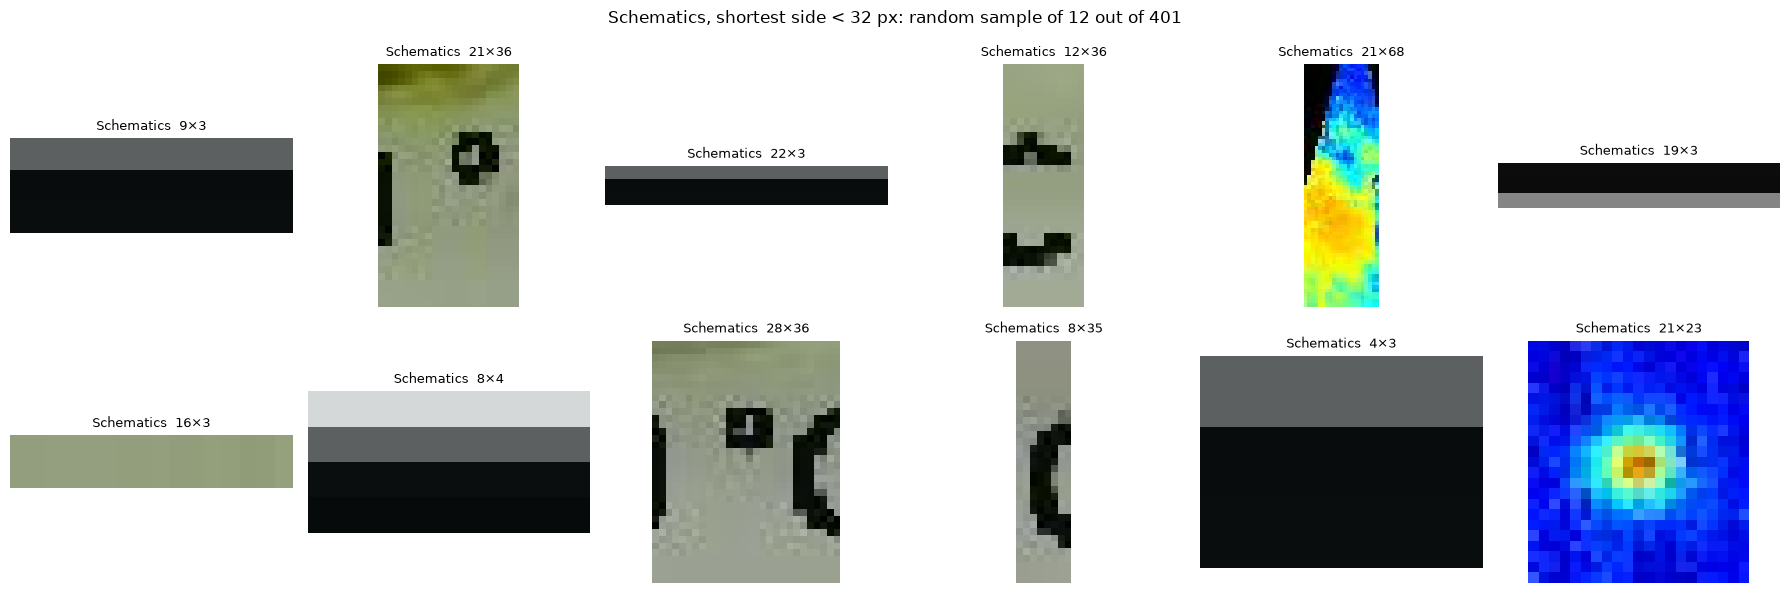

In [9]:
# Number of Schematics per shortest-side band, and one random sample (seed 42)
# of those below 32 px, the proposed threshold (MIN_SIDE_PX, next cell).
schem = df[kept & (df["origin"] == "Schematics")]
for lo, hi in [(1, 16), (16, 32), (32, 48), (48, 64), (64, 128)]:
    n = ((schem["min_side"] >= lo) & (schem["min_side"] < hi)).sum()
    print(f"Schematics, shortest side in [{lo}, {hi}) px: {n} images")

below = schem[schem["min_side"] < 32]
contact_sheet(below.sample(12, random_state=SEED), n_cols=6,
              title=f"Schematics, shortest side < 32 px: random sample of 12 out of {len(below)}")

In [10]:
MIN_SIDE_PX = 32   # proposed threshold, in pixels (shortest side)

too_small = (df["drop_reason"] == "") & (df["min_side"] < MIN_SIDE_PX)
df.loc[too_small, "drop_reason"] = "too_small"
print(f"{too_small.sum()} images marked too_small (< {MIN_SIDE_PX} px)")
df.loc[too_small, "origin"].value_counts()

401 images marked too_small (< 32 px)


origin
Schematics    401
Name: count, dtype: int64

What we observe:

- 401 images marked `too_small`, all Schematics.
- Below 128 px: 993 Schematics and 2 Photos; 0 in Painting, Sketch and Text.

### Extreme aspect ratios

Images with a ratio above 10:1 or below 1:10 are kept and documented, not removed.

In [11]:
kept = df["drop_reason"] == ""
ratio = df[["width", "height"]].max(axis=1) / df["min_side"]
extreme = kept & (ratio > 10)
print(f"{extreme.sum()} kept images with an aspect ratio above 10:1 or below 1:10 (not marked)")
df.loc[extreme, "origin"].value_counts().rename("count").to_frame()

31 kept images with an aspect ratio above 10:1 or below 1:10 (not marked)


,count
origin,
Schematics,29
Painting,2


What we observe:

- 31 kept images have a ratio above 10:1 or below 1:10: 29 Schematics, 2 Painting.

## Split

70 / 15 / 15, seed 42, after cleaning, stratified by origin (two calls to `train_test_split`).
Why by origin: Sketch is only 3.5 % of the kept images, so its share in test must be fixed for its error rate to be comparable.
A single split rather than k-fold, because k-fold multiplies the number of CNN trainings by k.

In [12]:
kept = df["drop_reason"] == ""
idx_train, idx_tmp = train_test_split(
    df.index[kept], test_size=0.30, stratify=df.loc[kept, "origin"], random_state=SEED)
idx_val, idx_test = train_test_split(
    idx_tmp, test_size=0.50, stratify=df.loc[idx_tmp, "origin"], random_state=SEED)

df["split"] = ""
df.loc[idx_train, "split"] = "train"
df.loc[idx_val, "split"] = "val"
df.loc[idx_test, "split"] = "test"

# Consistency checks
assert (df.loc[kept, "split"] != "").all(), "A kept file has no split!"
assert (df.loc[~kept, "split"] == "").all(), "A dropped file has a split!"
# Leakage check: an md5 must appear in a single split
splits_per_md5 = df[df["split"] != ""].groupby("md5")["split"].nunique()
assert (splits_per_md5 == 1).all(), "The same md5 is present in several splits!"
print(f"OK: no md5 in two splits ({splits_per_md5.size} distinct kept md5s)")

# Stratification check: share of each origin within each split
pd.crosstab(df.loc[kept, "origin"], df.loc[kept, "split"], normalize="columns").round(4)

OK: no md5 in two splits (40302 distinct kept md5s)


split,test,train,val
origin,,,
Painting,0.2481,0.2480,0.2480
Photo,0.2479,0.2480,0.2480
Schematics,0.2210,0.2210,0.2210
Sketch,0.0349,0.0349,0.0349
Text,0.2481,0.2481,0.2481


What we observe:

- No md5 is in two splits.
- Each origin has the same share in train, val and test to within 0.0001 (Sketch: 0.0349 in all three).

## Class balance

The test set keeps its natural imbalance (no 50/50 rebalancing).
Its majority-class rate is the accuracy of always answering "non-Photo": the floor every model must beat.

In [13]:
stats = pd.crosstab(df["origin"], df["drop_reason"]).drop(columns="", errors="ignore")
stats.columns = [f"dropped: {c}" for c in stats.columns]
stats.insert(0, "total", df.groupby("origin").size())
stats["kept"] = df[df["drop_reason"] == ""].groupby("origin").size()
for s in ["train", "val", "test"]:
    stats[s] = df[df["split"] == s].groupby("origin").size()
stats = stats.fillna(0).astype(int)
stats.loc["TOTAL"] = stats.sum()
display(stats)

test = df[df["split"] == "test"]
share = test["label"].value_counts(normalize=True)
print(f"Natural test set: {len(test)} images, Photo = {share.get(1, 0):.2%}, non-Photo = {share.get(0, 0):.2%}")
print(f"Majority-class rate (label {share.idxmax()}): {share.max():.4f}")

,total,dropped: exact_duplicate,dropped: too_small,kept,train,val,test
origin,,,,,,,
Painting,10000,4,0,9996,6997,1499,1500
Photo,9993,0,0,9993,6995,1499,1499
Schematics,10000,691,401,8908,6236,1336,1336
Sketch,1406,0,0,1406,984,211,211
Text,10000,1,0,9999,6999,1500,1500
TOTAL,41399,696,401,40302,28211,6045,6046


Natural test set: 6046 images, Photo = 24.79%, non-Photo = 75.21%
Majority-class rate (label 0): 0.7521


What we observe:

- Test set: 6,046 images, Photo = 24.79 %; majority-class rate 0.7521.
- Kept: 40,302 files (28,211 train, 6,045 val, 6,046 test).

## Metadata baseline

Depth-3 decision tree on width, height and ratio, trained on train and scored on test with `evaluate` (defined below).
Why: if size alone separates Photo from the rest, a CNN may learn the resolution instead of the content.

In [14]:
def evaluate(y_true, proba, origin, threshold=0.5):
    """Metrics for the Photo class (label 1), plus the error rate by origin."""
    y_true, proba, origin = np.asarray(y_true), np.asarray(proba).ravel(), np.asarray(origin)
    y_pred = (proba >= threshold).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, pos_label=1, average="binary", zero_division=0)
    errors = pd.Series(y_pred != y_true).groupby(origin).mean()
    return {
        "precision_photo": float(p),
        "recall_photo": float(r),
        "f1_photo": float(f1),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "pr_auc": float(average_precision_score(y_true, proba)),   # on probabilities, threshold-free
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1]),   # rows = true
        "error_rate_by_origin": errors.to_dict(),
    }

def meta(d):
    return np.column_stack([d["width"], d["height"], d["width"] / d["height"]])

train = df[df["split"] == "train"]
tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(meta(train), train["label"])
print(export_text(tree, feature_names=["width", "height", "ratio"]))

proba = tree.predict_proba(meta(test))[:, 1]
acc = ((proba >= 0.5).astype(int) == test["label"].values).mean()
res = evaluate(test["label"], proba, test["origin"])
print(f"Accuracy (natural test set): {acc:.4f}")
for k in ["precision_photo", "recall_photo", "f1_photo", "balanced_accuracy", "pr_auc"]:
    print(f"{k:18s}: {res[k]:.4f}")
print("Confusion matrix (rows = true 0/1, columns = predicted 0/1):\n", res["confusion_matrix"])
pd.Series(res["error_rate_by_origin"], name="error rate").round(4).to_frame()

|--- height <= 640.50
|   |--- width <= 422.50
|   |   |--- height <= 639.00
|   |   |   |--- class: 0
|   |   |--- height >  639.00
|   |   |   |--- class: 1
|   |--- width >  422.50
|   |   |--- width <= 640.50
|   |   |   |--- class: 1
|   |   |--- width >  640.50
|   |   |   |--- class: 0
|--- height >  640.50
|   |--- class: 0

Accuracy (natural test set): 0.9052
precision_photo   : 0.7399
recall_photo      : 0.9526
f1_photo          : 0.8329
balanced_accuracy : 0.9211
pr_auc            : 0.7357
Confusion matrix (rows = true 0/1, columns = predicted 0/1):
 [[4045  502]
 [  71 1428]]


,error rate
Painting,0.1427
Photo,0.0474
Schematics,0.2156
Sketch,0.0000
Text,0.0000


What we observe:

- Accuracy 0.9052, balanced accuracy 0.9211, Photo recall 0.9526, Photo precision 0.7399.
- Error rate: 0.0000 on Sketch and Text, 0.0474 on Photo, 0.1427 on Painting, 0.2156 on Schematics.
- The tree splits only on height and width; ratio does not appear.

## Export

In `protocol/manifest.csv`, `drop_reason` is empty for kept rows and `split` is empty for dropped rows.
The file is saved outside `data/` (ignored by git) so that it is versioned.

In [15]:
COLUMNS = ["path", "origin", "label", "ext", "width", "height", "mode", "md5", "drop_reason", "split"]
out = df[COLUMNS].copy()
out["width"] = out["width"].astype("Int64")   # integers, empty if unknown
out["height"] = out["height"].astype("Int64")
MANIFEST.parent.mkdir(exist_ok=True)
out.to_csv(MANIFEST, index=False)

# Read the file back to check it is usable as is
reread = pd.read_csv(MANIFEST, dtype={"md5": str}, keep_default_na=False)
assert len(reread) == len(df)
assert (reread["drop_reason"] == "").sum() == (df["drop_reason"] == "").sum()
assert set(reread["drop_reason"]) <= {
    "", "unreadable", "exact_duplicate", "label_conflict", "too_small", "not_an_image"}
print(f"{MANIFEST} written: {len(out)} rows, {(reread['drop_reason'] == '').sum()} kept")
print(out["drop_reason"].replace("", "(kept)").value_counts().to_string())

protocol/manifest.csv written: 41399 rows, 40302 kept


drop_reason
(kept)             40302
exact_duplicate      696
too_small            401
